<a href="https://colab.research.google.com/github/Emil-888/Data-Science/blob/main/Copia_de_Copia_de_01_eda_missings_outliers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploración de Datos, Valores Faltantes y Outliers con Python

**JUMP Educación** · Clase práctica · **4 horas** (versión extendida)

| Bloque | Tema | Tiempo |
|--------|------|--------|
| 0 | Setup y dataset | 15 min |
| 1 | Exploración de datos (EDA) | 70 min |
| 2 | Valores faltantes | 70 min |
| 3 | Detección y filtrado de outliers | 65 min |
| 4 | Mini-proyecto integrador | 40 min |

**Objetivo:** al terminar, vas a poder inspeccionar un dataset tabular, diagnosticar y tratar missings, detectar outliers con IQR, Z-score y percentiles, comparar estrategias, y dejar una tabla limpia lista para modelar.

**Stack:** `pandas`, `numpy`, `matplotlib`, `seaborn`

> Esta versión incluye **más ejemplos paso a paso**, comparaciones lado a lado y ejercicios extra para practicar en clase o de tarea.


---
## Bloque 0 — Setup (15 min)

Importamos librerías y fijamos semilla para reproducibilidad. El dataset se **genera en memoria**: no hace falta descargar nada.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Reproducibilidad
RNG = np.random.default_rng(42)

# Estilo de gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 13

print("pandas:", pd.__version__)
print("numpy:", np.__version__)


pandas: 2.2.3
numpy: 2.1.3


### Dataset: `clientes_credito`

Simulamos una cartera de clientes de un producto de crédito. Incluye **missings intencionales** (MCAR, MAR, MNAR) y **outliers** (errores de negocio + extremos reales) para practicar.

**Diccionario de variables:**

| Columna | Tipo | Descripción |
|---------|------|-------------|
| `cliente_id` | ID | Identificador único |
| `edad` | num | Edad del cliente |
| `ingreso_mensual` | num | Ingreso mensual declarado |
| `score_crediticio` | num | Score ~300–850 |
| `antiguedad_meses` | num | Antigüedad como cliente |
| `cuotas_atrasadas` | num | Cantidad de cuotas atrasadas |
| `monto_solicitado` | num | Monto del préstamo pedido |
| `segmento` | cat | Segmento de riesgo A–D |
| `ciudad` | cat | Ciudad / zona |


In [4]:
n = 1200

edad = RNG.normal(38, 10, n).clip(18, 75).round().astype(float)
ingreso_mensual = RNG.lognormal(mean=10.8, sigma=0.45, size=n).round(2)
score_crediticio = RNG.normal(650, 80, n).clip(300, 850).round().astype(float)
antiguedad_meses = RNG.integers(0, 120, n).astype(float)
cuotas_atrasadas = RNG.poisson(1.2, n).astype(float)
monto_solicitado = (ingreso_mensual * RNG.uniform(2, 8, n)).round(2)
segmento = RNG.choice(["A", "B", "C", "D"], size=n, p=[0.15, 0.35, 0.35, 0.15])
ciudad = RNG.choice(
    ["CABA", "GBA Norte", "GBA Sur", "Córdoba", "Rosario", "Mendoza"],
    size=n,
)

df = pd.DataFrame({
    "cliente_id": [f"C{i:04d}" for i in range(1, n + 1)],
    "edad": edad,
    "ingreso_mensual": ingreso_mensual,
    "score_crediticio": score_crediticio,
    "antiguedad_meses": antiguedad_meses,
    "cuotas_atrasadas": cuotas_atrasadas,
    "monto_solicitado": monto_solicitado,
    "segmento": segmento,
    "ciudad": ciudad,
})

# --- Missings intencionales ---
# MCAR: al azar en score
idx_mcar = RNG.choice(df.index, size=int(0.06 * n), replace=False)
df.loc[idx_mcar, "score_crediticio"] = np.nan

# MAR: ingresos faltan más en segmento D
idx_mar = df.index[df["segmento"] == "D"]
idx_mar = RNG.choice(idx_mar, size=int(0.35 * len(idx_mar)), replace=False)
df.loc[idx_mar, "ingreso_mensual"] = np.nan

# MNAR: montos muy altos tienen más chance de faltar
alto = df["monto_solicitado"] > df["monto_solicitado"].quantile(0.90)
idx_mnar = df.index[alto]
idx_mnar = RNG.choice(idx_mnar, size=int(0.40 * len(idx_mnar)), replace=False)
df.loc[idx_mnar, "monto_solicitado"] = np.nan

# Categoría con missings
idx_cat = RNG.choice(df.index, size=int(0.04 * n), replace=False)
df.loc[idx_cat, "ciudad"] = np.nan

# --- Outliers intencionales ---
df.loc[RNG.choice(df.index, 8, replace=False), "edad"] = RNG.choice(
    [5, 12, 110, 130], size=8
)
df.loc[RNG.choice(df.index, 10, replace=False), "ingreso_mensual"] = RNG.uniform(
    2_500_000, 8_000_000, 10
).round(2)
df.loc[RNG.choice(df.index, 6, replace=False), "score_crediticio"] = RNG.choice(
    [-50, 0, 999, 1200], size=6
)

print(df.shape)
df.head()


(1200, 9)


,cliente_id,edad,ingreso_mensual,score_crediticio,antiguedad_meses,cuotas_atrasadas,monto_solicitado,segmento,ciudad
0,C0001,41.0,27034.16,NaN,91.0,0.0,108719.53,C,GBA Norte
1,C0002,28.0,39387.85,728.0,11.0,1.0,133927.76,C,NaN
2,C0003,46.0,59225.18,672.0,71.0,2.0,235033.31,B,GBA Sur
3,C0004,47.0,46813.25,594.0,41.0,0.0,154021.68,C,Córdoba
4,C0005,18.0,NaN,581.0,44.0,0.0,97816.46,D,GBA Norte


> **Tip docente:** guardá una copia cruda. Siempre trabajamos sobre una copia para poder comparar antes/después.


In [5]:
df_raw = df.copy()
print(f'Filas:{df_raw.shape[0]},Columnas:{df_raw.shape}')


Filas:1200,Columnas:(1200, 9)


### Ejemplo extra — Inventario rápido del dataset

Antes del EDA profundo, conviene un **one-liner de salud**: shape, dtypes, missings totales y rango de IDs.


In [6]:
def dataset_healthcheck(frame: pd.DataFrame, id_col: str = "cliente_id") -> None:
    print("=== HEALTHCHECK ===")
    print(f"shape: {frame.shape}")
    print(f"dtypes:\n{frame.dtypes.value_counts().to_string()}")
    print(f"missings totales: {int(frame.isna().sum().sum())}")
    print(f"filas 100% completas: {(~frame.isna().any(axis=1)).sum()}")
    if id_col in frame.columns:
        print(f"{id_col} únicos: {frame[id_col].nunique()} / {len(frame)}")

dataset_healthcheck(df)


=== HEALTHCHECK ===
shape: (1200, 9)
dtypes:
float64    6
object     3
missings totales: 230
filas 100% completas: 981
cliente_id únicos: 1200 / 1200


---
## Bloque 1 — Exploración de datos / EDA (70 min)

### 1.1 Primeras miradas: `shape`, `dtypes`, `info`, `head/tail`

El objetivo de esta etapa no es limpiar todavía: es **entender** qué hay, qué tipos tenemos y dónde aparecen rarezas.


In [7]:
print(f"Shape: {df.shape}")
print(df.dtypes)
df.info()


Shape: (1200, 9)
cliente_id           object
edad                float64
ingreso_mensual     float64
score_crediticio    float64
antiguedad_meses    float64
cuotas_atrasadas    float64
monto_solicitado    float64
segmento             object
ciudad               object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cliente_id        1200 non-null   object 
 1   edad              1200 non-null   float64
 2   ingreso_mensual   1138 non-null   float64
 3   score_crediticio  1128 non-null   float64
 4   antiguedad_meses  1200 non-null   float64
 5   cuotas_atrasadas  1200 non-null   float64
 6   monto_solicitado  1152 non-null   float64
 7   segmento          1200 non-null   object 
 8   ciudad            1152 non-null   object 
dtypes: float64(6), object(3)
memory usage: 84.5+ KB


In [8]:
display(df.head(2))
display(df.tail(3))
display(df.sample(3, random_state=42)) # random state es la semilla de reproducibilidad

,cliente_id,edad,ingreso_mensual,score_crediticio,antiguedad_meses,cuotas_atrasadas,monto_solicitado,segmento,ciudad
0,C0001,41.0,27034.16,NaN,91.0,0.0,108719.53,C,GBA Norte
1,C0002,28.0,39387.85,728.0,11.0,1.0,133927.76,C,NaN


,cliente_id,edad,ingreso_mensual,score_crediticio,antiguedad_meses,cuotas_atrasadas,monto_solicitado,segmento,ciudad
1197,C1198,29.0,45139.64,604.0,15.0,1.0,336436.77,C,CABA
1198,C1199,53.0,36684.38,508.0,4.0,3.0,228115.71,C,GBA Sur
1199,C1200,27.0,63889.89,762.0,107.0,1.0,486558.07,C,CABA


,cliente_id,edad,ingreso_mensual,score_crediticio,antiguedad_meses,cuotas_atrasadas,monto_solicitado,segmento,ciudad
1178,C1179,42.0,49970.29,695.0,11.0,1.0,195682.32,D,Córdoba
865,C0866,46.0,45351.93,682.0,103.0,2.0,144070.48,B,Mendoza
101,C0102,51.0,19187.59,670.0,116.0,3.0,71555.33,D,GBA Sur


### Ejemplo — Selección de columnas por tipo y por nombre

En proyectos reales vas a filtrar columnas todo el tiempo. Practiquemos patrones útiles de `pandas`.


In [9]:
# Por tipo
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(include = ["object","category"]).columns.tolist()
print("Numericas",num_cols)
print("Categoricas", cat_cols)

#Por patron de nombre
cols_con_score = [col for col in df.columns if "score" in col.lower()]
print("Scores", cols_con_score)

#Vista reducida
display(df.loc[:4, ["cliente_id", "segmento", "edad","score_crediticio"]])



Numericas ['edad', 'ingreso_mensual', 'score_crediticio', 'antiguedad_meses', 'cuotas_atrasadas', 'monto_solicitado']
Categoricas ['cliente_id', 'segmento', 'ciudad']
Scores ['score_crediticio']


,cliente_id,segmento,edad,score_crediticio
0,C0001,C,41.0,NaN
1,C0002,C,28.0,728.0
2,C0003,B,46.0,672.0
3,C0004,C,47.0,594.0
4,C0005,D,18.0,581.0


In [10]:
display(df.head())

,cliente_id,edad,ingreso_mensual,score_crediticio,antiguedad_meses,cuotas_atrasadas,monto_solicitado,segmento,ciudad
0,C0001,41.0,27034.16,NaN,91.0,0.0,108719.53,C,GBA Norte
1,C0002,28.0,39387.85,728.0,11.0,1.0,133927.76,C,NaN
2,C0003,46.0,59225.18,672.0,71.0,2.0,235033.31,B,GBA Sur
3,C0004,47.0,46813.25,594.0,41.0,0.0,154021.68,C,Córdoba
4,C0005,18.0,NaN,581.0,44.0,0.0,97816.46,D,GBA Norte


### 1.2 Estadísticos descriptivos

- Numéricas → `describe()`
- Categóricas → `describe(include="object")` o `value_counts()`

Además vamos a mirar **percentiles**, **asimetría** y **curtosis**: ayudan a anticipar outliers y sesgo.


In [11]:
display(df.describe())
display(df.describe(include="object"))


,edad,ingreso_mensual,score_crediticio,antiguedad_meses,cuotas_atrasadas,monto_solicitado
count,1200.000000,1.138000e+03,1128.000000,1200.000000,1200.000000,1.152000e+03
mean,38.206667,1.042788e+05,650.983156,58.752500,1.141667,2.527593e+05
std,11.218311,5.733112e+05,90.440511,33.972754,1.037221,1.494460e+05
min,5.000000,1.234861e+04,-50.000000,0.000000,0.000000,3.529637e+04
25%,31.000000,3.536095e+04,597.000000,29.000000,0.000000,1.469597e+05
50%,38.000000,4.885540e+04,652.000000,59.000000,1.000000,2.223437e+05
75%,44.000000,6.533825e+04,708.250000,86.250000,2.000000,3.257400e+05
max,130.000000,7.862320e+06,1200.000000,119.000000,5.000000,1.305347e+06


,cliente_id,segmento,ciudad
count,1200,1200,1152
unique,1200,4,6
top,C1184,B,CABA
freq,1,427,209


In [12]:
#Percentiles
percentiles = df[num_cols].quantile([0.1, 0.05,0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
display(percentiles.round(2))


,edad,ingreso_mensual,score_crediticio,antiguedad_meses,cuotas_atrasadas,monto_solicitado
0.10,25.0,26044.38,548.70,11.00,0.0,98160.59
0.05,21.0,21964.46,517.00,6.95,0.0,79587.20
0.25,31.0,35360.95,597.00,29.00,0.0,146959.72
0.50,38.0,48855.40,652.00,59.00,1.0,222343.66
0.75,44.0,65338.25,708.25,86.25,2.0,325740.04
0.90,51.0,85213.77,755.30,106.00,3.0,420732.17
0.95,55.0,104662.22,782.00,113.00,3.0,523302.00
0.99,63.0,176034.83,845.38,118.00,4.0,795198.42


In [13]:
# Frecuencias de las categorias
for col in ["segmento", "ciudad"]:
  print(f"/n===={col}=====")
  print(df[col].value_counts(dropna=False))
  print("Proporcion:")
  print(df[col].value_counts(dropna=False, normalize=True).round(4)*100)


/n====segmento=====
segmento
B    427
C    426
D    179
A    168
Name: count, dtype: int64
Proporcion:
segmento
B    35.58
C    35.50
D    14.92
A    14.00
Name: proportion, dtype: float64
/n====ciudad=====
ciudad
CABA         209
Córdoba      199
Mendoza      190
GBA Norte    187
GBA Sur      187
Rosario      180
NaN           48
Name: count, dtype: int64
Proporcion:
ciudad
CABA         17.42
Córdoba      16.58
Mendoza      15.83
GBA Norte    15.58
GBA Sur      15.58
Rosario      15.00
NaN           4.00
Name: proportion, dtype: float64


### Ejemplo — Tablas cruzadas y agregaciones

`crosstab` y `groupby` son el corazón del EDA de negocio: ¿el score cambia por segmento? ¿el monto por ciudad?


In [14]:
# Crosstab: segmento x ciudad (conteos)
ct = pd.crosstab(df["segmento"], df["ciudad"], dropna=False)
display(ct)

# % por fila (distribucion de ciudades dentro de cada segmento)
ct_pct = pd.crosstab(df["segmento"], df["ciudad"], dropna=False, normalize="index").round(2)
print("Proporcion de ciudad dentro de cada segmento")
display(ct_pct)

ciudad,CABA,Córdoba,GBA Norte,GBA Sur,Mendoza,Rosario,NaN
segmento,,,,,,,
A,32,28,20,21,26,31,10
B,87,66,57,71,75,55,16
C,61,76,80,69,57,67,16
D,29,29,30,26,32,27,6


Proporcion de ciudad dentro de cada segmento


ciudad,CABA,Córdoba,GBA Norte,GBA Sur,Mendoza,Rosario,NaN
segmento,,,,,,,
A,0.19,0.17,0.12,0.12,0.15,0.18,0.06
B,0.20,0.15,0.13,0.17,0.18,0.13,0.04
C,0.14,0.18,0.19,0.16,0.13,0.16,0.04
D,0.16,0.16,0.17,0.15,0.18,0.15,0.03


In [17]:
# Groupby : perfil por segmento
perfil_segmento = (
    df.groupby("segmento")
    .agg(
        n=("cliente_id", "count"),
        edad_media=("edad", "mean"),
        score_mediana=("score_crediticio", "median"),
        ingreso_mediana=("ingreso_mensual", "median"),
        monto_mediana=("monto_solicitado", "median"),
        atrasos_prom=("cuotas_atrasadas", "mean"),
    )
    .reindex(["A", "B", "C", "D"])
    .round(2)
)
display(perfil_segmento)

# Groupby multinivel: segmento + ciudad
top_ciudades = (
    df.groupby(["segmento", "ciudad"])["monto_solicitado"]
    .median()
    .unstack()
    .round(0)
)
print("Mediana de monto_solicitado por segmento x ciudad:")
display(top_ciudades)

,n,edad_media,score_mediana,ingreso_mediana,monto_mediana,atrasos_prom
segmento,,,,,,
A,168,38.20,651.0,50864.06,213921.26,1.18
B,427,38.73,653.0,51152.50,236344.84,1.15
C,426,37.31,648.0,46670.30,211879.63,1.15
D,179,39.10,659.5,44524.19,231588.04,1.04


Mediana de monto_solicitado por segmento x ciudad:


ciudad,CABA,Córdoba,GBA Norte,GBA Sur,Mendoza,Rosario
segmento,,,,,,
A,205343.0,195772.0,195656.0,219610.0,248081.0,252539.0
B,243226.0,277817.0,273479.0,218904.0,189075.0,235977.0
C,241146.0,204307.0,207220.0,228116.0,211709.0,196034.0
D,218880.0,227666.0,246661.0,286055.0,213644.0,210685.0


### 1.3 Cardinalidad, duplicados y rangos de negocio


In [18]:
# Cardinalidad
card = pd.DataFrame({
    "n_unique": df.nunique(dropna = False),
    "pct_unique": (df.nunique() / len(df)).round(2) * 100
})
display(card)

,n_unique,pct_unique
cliente_id,1200,100.0
edad,53,4.0
ingreso_mensual,1138,95.0
score_crediticio,334,28.0
antiguedad_meses,120,10.0
cuotas_atrasadas,6,0.0
monto_solicitado,1153,96.0
segmento,4,0.0
ciudad,7,0.0


In [19]:
# Duplicados
print(f"Filas duplicadas: {df.duplicated().sum()}")

Filas duplicadas: 0


### Ejemplo — Filtrado exploratorio con máscaras

Antes de modelar, filtrá casos raros solo para **inspeccionarlos** (todavía no los borres).


In [21]:
# Clientes con score fuera de rango de negocio
score_raro = df[(df["score_crediticio"] < 300) | (df["score_crediticio"] > 850)]
display(score_raro)

,cliente_id,edad,ingreso_mensual,score_crediticio,antiguedad_meses,cuotas_atrasadas,monto_solicitado,segmento,ciudad
156,C0157,39.0,41386.27,1200.0,37.0,1.0,325265.38,D,CABA
345,C0346,18.0,44068.63,0.0,52.0,1.0,187106.83,C,GBA Sur
374,C0375,44.0,25485.89,999.0,19.0,1.0,202153.37,C,Córdoba
530,C0531,34.0,47056.68,-50.0,13.0,2.0,317063.63,B,Mendoza
539,C0540,30.0,51539.70,-50.0,8.0,0.0,367612.17,A,CABA
648,C0649,40.0,41231.28,0.0,29.0,1.0,192250.88,B,Córdoba


In [20]:
#Top_ingresos
p99= df["ingreso_mensual"].quantile(0.99)
top_ingresos = df[df["ingreso_mensual"] >= p99].sort_values("ingreso_mensual", ascending=False)
display(top_ingresos)

,cliente_id,edad,ingreso_mensual,score_crediticio,antiguedad_meses,cuotas_atrasadas,monto_solicitado,segmento,ciudad
113,C0114,24.0,7862320.05,714.0,22.0,0.0,328408.04,B,Córdoba
1133,C1134,52.0,7837381.04,678.0,17.0,2.0,289555.58,C,Mendoza
339,C0340,44.0,7651171.74,761.0,72.0,0.0,NaN,A,Córdoba
340,C0341,18.0,6936408.31,582.0,31.0,1.0,337212.15,C,Mendoza
1031,C1032,40.0,6740681.48,762.0,24.0,1.0,114346.70,B,GBA Sur
1034,C1035,33.0,6132288.98,548.0,101.0,1.0,192643.23,B,CABA
917,C0918,43.0,6084539.61,596.0,45.0,0.0,130120.71,C,Rosario
390,C0391,18.0,3779092.28,768.0,42.0,0.0,208124.99,A,GBA Norte
206,C0207,30.0,3267287.95,NaN,111.0,1.0,114078.88,A,NaN
585,C0586,58.0,2699126.47,614.0,16.0,2.0,615983.04,B,Rosario


### 1.4 Visualizaciones exploratorias

Regla práctica: **una pregunta → un gráfico**. Empezamos por distribuciones univariadas y después cruzamos variables.


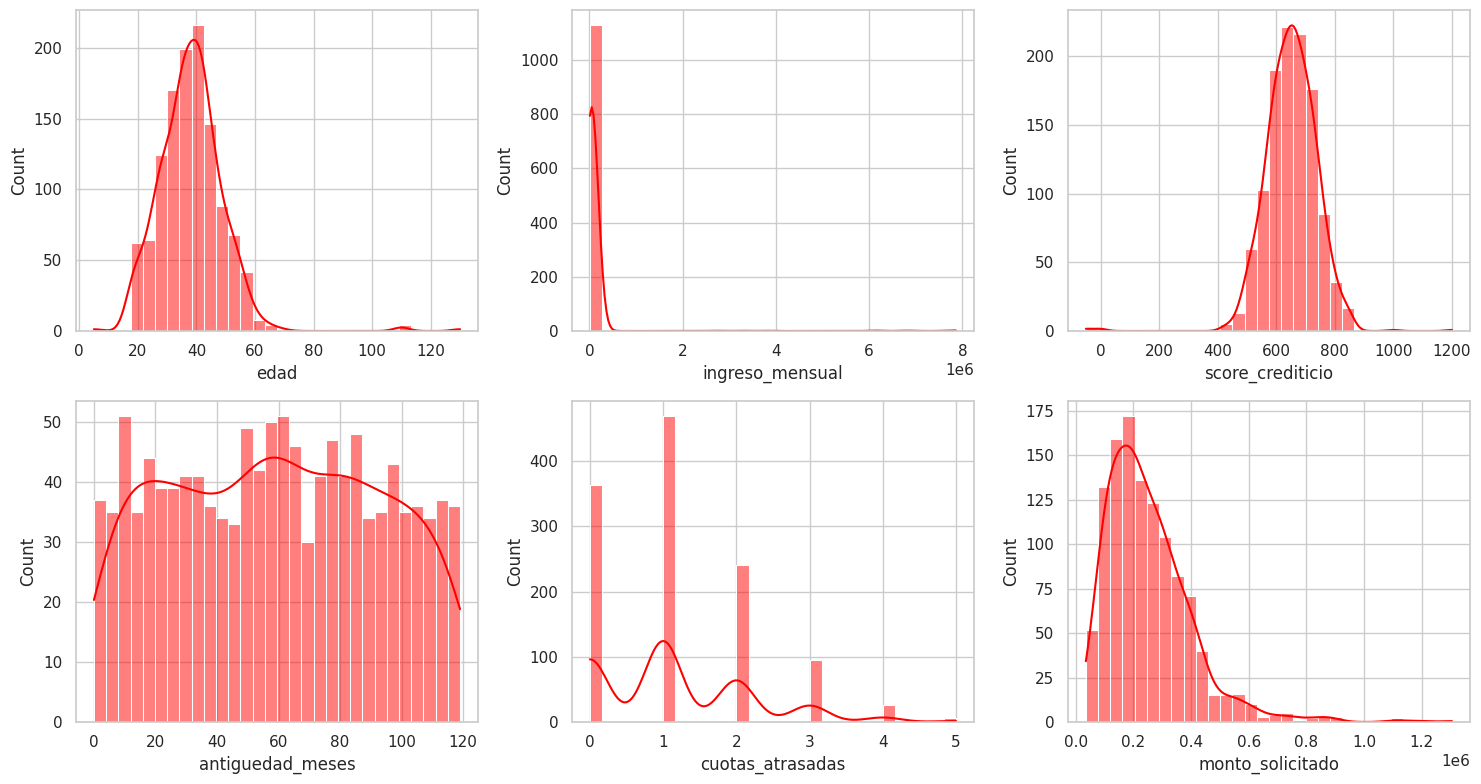

In [23]:
# Histogramas de variables clave
fig, axes = plt.subplots(2, 3, figsize=(15,8))
plots_cols = [
    "edad",
    "ingreso_mensual",
    "score_crediticio",
    "antiguedad_meses",
    "cuotas_atrasadas",
    "monto_solicitado",
]

for ax, col in zip(axes.ravel(), plots_cols):
    sns.histplot(df[col].dropna(), bins=30, kde=True ,ax=ax, color = "red"   )
plt.tight_layout()
plt.show()


### Ejemplo — Escala log en variables sesgadas

`ingreso_mensual` y `monto_solicitado` suelen ser lognormales. Comparar histograma crudo vs `log1p` cambia la lectura.


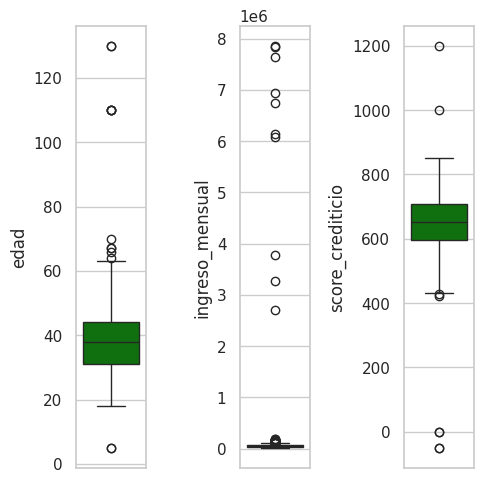

In [25]:
# bosplots sirve para detectar
fig, axes = plt.subplots(1, 3, figsize=(5,5))
for ax, col in zip(axes, ["edad", "ingreso_mensual", "score_crediticio"]):
    sns.boxplot(y = df[col], ax=ax, color= "green")
plt.tight_layout()
plt.show()

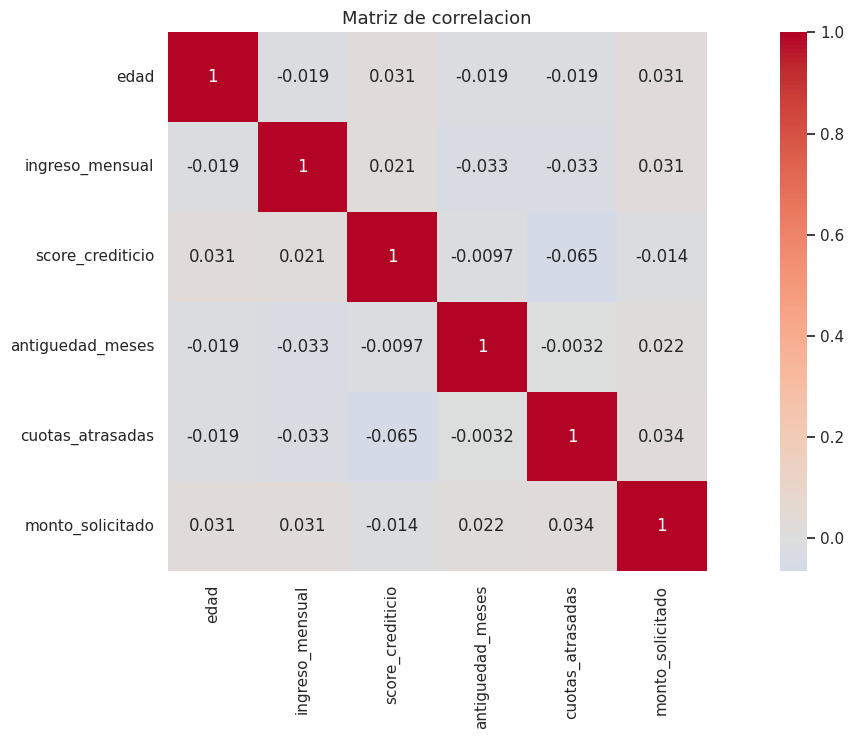

Top correlaciones:
score_crediticio  cuotas_atrasadas    0.064930
cuotas_atrasadas  monto_solicitado    0.033872
ingreso_mensual   antiguedad_meses    0.033463
                  cuotas_atrasadas    0.033038
edad              monto_solicitado    0.031117
ingreso_mensual   monto_solicitado    0.030960
edad              score_crediticio    0.030950
antiguedad_meses  monto_solicitado    0.022434
ingreso_mensual   score_crediticio    0.021322
edad              antiguedad_meses    0.019147
dtype: float64


In [26]:
# Relacion entre variables numericas (solo se comparan filas completas)

corr = df[num_cols].corr(numeric_only=True)
plt.figure(figsize=(19, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", center = 0, square = True)
plt.title("Matriz de correlacion")
plt.show()
#Top Correlaciones absolutas (sin la diagonal)
corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .abs()
    .sort_values(ascending=False)
)
print("Top correlaciones:")
print(corr_pairs.head(10))


### ✅ Ejercicio 1 (10 min)

1. ¿Qué variable numérica tiene mayor coeficiente de variación (`std/mean`)?
2. ¿Hay alguna ciudad con menos del 10% de los registros (incluyendo NaN)?
3. Graficá un `countplot` de `segmento` y anotá qué segmento predomina.

Escribí tu código abajo antes de mirar la solución.


In [ ]:
# Escribí tu solución del Ejercicio 1 acá





#### Solución — Ejercicio 1


### ✅ Ejercicio 1B — Extra (8 min)

1. Calculá la **mediana de `score_crediticio` por `ciudad`** y ordená de mayor a menor.
2. ¿Qué segmento tiene mayor promedio de `cuotas_atrasadas`?
3. Armá un scatter de `edad` vs `score_crediticio` coloreado por `segmento` (usá una muestra de 400 filas).


In [ ]:
# Escribí tu solución del Ejercicio 1B acá





#### Solución — Ejercicio 1B


---
## Bloque 2 — Valores faltantes (70 min)

### 2.1 Tipos de missingness (concepto)

| Tipo | Significado | Ejemplo en este dataset |
|------|-------------|-------------------------|
| **MCAR** | Missing Completely At Random | `score_crediticio` al azar |
| **MAR** | Missing At Random (depende de otras vars observadas) | `ingreso_mensual` más faltante en segmento D |
| **MNAR** | Missing Not At Random (depende del valor no observado) | `monto_solicitado` alto más propenso a faltar |

El tipo **condiciona** la estrategia: drop, imputación simple, imputación por grupo, o modelar el missing.

**Analogía rápida:**
- MCAR → se te borró una celda al azar al copiar el Excel.
- MAR → los clientes del segmento D no cargan el ingreso en el formulario.
- MNAR → quien pide montos muy altos evita declarar el monto exacto.


### 2.2 Diagnóstico: cuántos, dónde y en qué patrón


In [28]:
def missing_report(frame: pd.DataFrame) -> pd.DataFrame:
  miss = frame.isna().sum()
  report = pd.DataFrame(
      {
          "n_missing": miss,
          "pct_missing": (miss / len(frame) * 100).round(2),
      }
  ).sort_values("pct_missing", ascending=False)
  return report[report["pct_missing"] > 0]

missing_report(df)

,n_missing,pct_missing
score_crediticio,72,6.00
ingreso_mensual,62,5.17
ciudad,48,4.00
monto_solicitado,48,4.00


### Ejemplo — ¿Qué columnas faltan juntas?

A veces el missing viene en **paquetes** (ej. un formulario incompleto). Contar combinaciones ayuda a decidir si dropear filas o imputar.


### 2.3 Estrategias de tratamiento

Regla práctica:

1. **Columna con >40–50% missing** y poco valor → considerar dropear la columna.
2. **Filas con muchos missings** → dropear filas (si el % es chico).
3. **Numéricas** → mediana (robusta a outliers) o media; mejor **por grupo** si hay MAR.
4. **Categóricas** → moda, o categoría explícita `"Desconocido"`.
5. Documentá siempre qué hiciste.

> No hay una única respuesta correcta: depende del objetivo (análisis descriptivo vs modelo predictivo).


### Ejemplo — ¿Cuánto perdemos si solo hacemos `dropna`?

Antes de imputar, midamos el costo de borrar filas incompletas.


In [29]:
n0 = len(df)
how_any = len(df.dropna(how="any"))
how_all = len(df.dropna(how="all"))
subset_score = len(df.dropna(subset=["score_crediticio"]))
subset_clave = len(df.dropna(subset=["ingreso_mensual","monto_solicitado"]))
costo_drop = pd.DataFrame(
    {
        "estrategia": [
            "dropna(how=any)",
            "dropna(how=all)",
            "dropna(subset=[score_crediticio])",
            "dropna(subset=[ingreso + monto])"
        ],
        "filas_restantes": [how_any, how_all, subset_score, subset_clave],

    }
)
costo_drop["filas_perdidas"] = n0 - costo_drop["filas_restantes"]
costo_drop["pct_perdidas"] = (costo_drop["filas_perdidas"] / n0 * 100).round(2)
display(costo_drop)


,estrategia,filas_restantes,filas_perdidas,pct_perdidas
0,dropna(how=any),981,219,18.25
1,dropna(how=all),1200,0,0.00
2,dropna(subset=[score_crediticio]),1128,72,6.00
3,dropna(subset=[ingreso + monto]),1091,109,9.08


### Ejemplo — Comparar media vs mediana vs moda (antes de elegir)

Para variables con outliers, media y mediana divergen. Por eso la mediana suele ser más segura.


Mediana de ingreso en segmento D bajo distintas imputaciones:


,solo_observados,imp_mediana_global,imp_mediana_seg,imp_media_seg
0,44524.19,48855.4,44524.19,51064.78


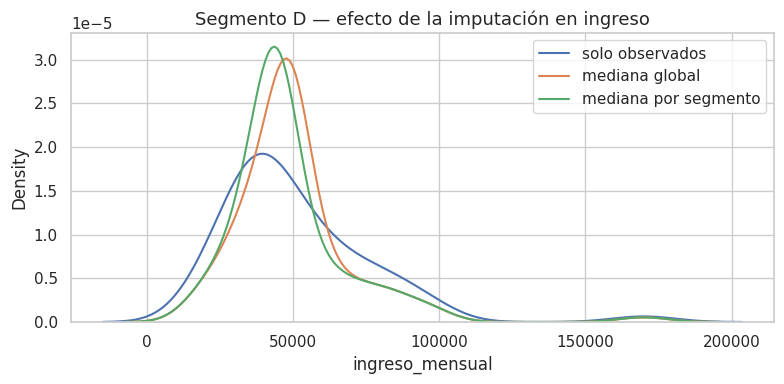

In [30]:
# Partimos de df_raw otra vez para el experimento
exp = df_raw.copy()

# Estrategia 1: mediana global
exp["ingreso_global"] = exp["ingreso_mensual"].fillna(exp["ingreso_mensual"].median())

# Estrategia 2: mediana por segmento
exp["ingreso_por_seg"] = exp.groupby("segmento")["ingreso_mensual"].transform(
    lambda s: s.fillna(s.median())
)

# Estrategia 3: media por segmento (más sensible a outliers)
exp["ingreso_media_seg"] = exp.groupby("segmento")["ingreso_mensual"].transform(
    lambda s: s.fillna(s.mean())
)

# Miramos solo segmento D (donde había más missings)
d = exp[exp["segmento"] == "D"]
cmp_d = pd.DataFrame({
    "solo_observados": [d["ingreso_mensual"].median()],
    "imp_mediana_global": [d["ingreso_global"].median()],
    "imp_mediana_seg": [d["ingreso_por_seg"].median()],
    "imp_media_seg": [d["ingreso_media_seg"].median()],
}).round(2)
print("Mediana de ingreso en segmento D bajo distintas imputaciones:")
display(cmp_d)

# Visual: distribución en D
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(d["ingreso_mensual"].dropna(), label="solo observados", ax=ax)
sns.kdeplot(d["ingreso_global"], label="mediana global", ax=ax)
sns.kdeplot(d["ingreso_por_seg"], label="mediana por segmento", ax=ax)
ax.legend()
ax.set_title("Segmento D — efecto de la imputación en ingreso")
plt.tight_layout()
plt.show()

### Ejemplo — ¿Por qué imputar ingreso por segmento y no global?

Comparemos tres estrategias y miremos el sesgo introducido en el segmento D.


### Ejemplo — Flag de missing como feature

Cuando sospechás MNAR, el hecho de que **faltara** el valor puede ser informativo para un modelo.


### ✅ Ejercicio 2 (12 min)

1. Compará la mediana de `ingreso_mensual` **antes** (solo observados) vs **después** de imputar. ¿Se movió mucho?
2. Probá una alternativa: imputar `score_crediticio` con la **media** en lugar de la mediana. ¿Qué cambia?
3. (Opcional) Creá un flag `score_era_na` antes de imputar sobre `df_raw` y contá cuántos 1 hay.


In [ ]:
# Escribí tu solución del Ejercicio 2 acá





#### Solución — Ejercicio 2


### ✅ Ejercicio 2B — Extra (10 min)

1. Imputá `ciudad` con la **moda** (en lugar de `"Desconocido"`) sobre una copia de `df_raw`. ¿Qué valor elige?
2. Calculá el % de missing de `ingreso_mensual` **por ciudad** (dropna=False en el groupby de ciudad original).
3. Dropear solo las filas con **2 o más** missings en `df_raw`. ¿Cuántas filas quedan?


In [ ]:
# Escribí tu solución del Ejercicio 2B acá





#### Solución — Ejercicio 2B


---
## Bloque 3 — Outliers: detección y filtrado (65 min)

### 3.1 ¿Qué es un outlier?

Un valor **atípico** respecto de la distribución esperada o de las reglas de negocio.

- **Error de datos:** edad = 130, score = -50 → corregir o eliminar.
- **Caso legítimo extremo:** ingreso muy alto → a veces se **winsoriza**, se transforma (`log`) o se modela aparte.

Métodos que vamos a usar:

1. **Reglas de negocio** (dominio)
2. **IQR** (Tukey): robusto, no asume normalidad
3. **Z-score**: asume ~campana; sensible a extremos
4. **Percentiles** (P1–P99): simple y muy usado en industria
5. **Z-score modificado (MAD)**: más robusto que el Z clásico


### 3.2 Reglas de negocio primero

Si el valor es imposible (edad 5, score -50), no hace falta un test estadístico: es un error.


In [33]:
def flag_businnes_outliers(frame: pd.DataFrame)-> pd.DataFrame:
  bad_edad = (frame["edad"] < 18) | (frame["edad"] > 100)
  bad_score = (frame["score_crediticio"] < 300) | (frame["score_crediticio"] > 850)
  return frame[bad_edad | bad_score]

out = flag_businnes_outliers(df)
print("Outliers de negocio:", len(out))
display(out)

Outliers de negocio: 14


,cliente_id,edad,ingreso_mensual,score_crediticio,antiguedad_meses,cuotas_atrasadas,monto_solicitado,segmento,ciudad
156,C0157,39.0,41386.27,1200.0,37.0,1.0,325265.38,D,CABA
194,C0195,5.0,21119.50,521.0,33.0,1.0,79200.84,A,Rosario
202,C0203,130.0,44719.67,643.0,23.0,1.0,127100.73,B,Rosario
345,C0346,18.0,44068.63,0.0,52.0,1.0,187106.83,C,GBA Sur
374,C0375,44.0,25485.89,999.0,19.0,1.0,202153.37,C,Córdoba
530,C0531,34.0,47056.68,-50.0,13.0,2.0,317063.63,B,Mendoza
539,C0540,30.0,51539.70,-50.0,8.0,0.0,367612.17,A,CABA
595,C0596,5.0,42337.81,589.0,69.0,0.0,145623.81,B,Córdoba
648,C0649,40.0,41231.28,0.0,29.0,1.0,192250.88,B,Córdoba
789,C0790,110.0,26579.37,541.0,54.0,1.0,163873.06,C,GBA Sur


### Ejemplo — Separar error de edad vs error de score


### 3.3 Método IQR


In [35]:
def iqr_bounds(series: pd.Series, k: float = 1.5):
  q1 = series.quantile(0.25)
  q3 = series.quantile(0.75)
  iqr = q3 - q1
  low = q1 - k * iqr
  high = q3 + k * iqr
  return low, high, q1, q3, iqr

def flag_iqr(series: pd.Series, k: float = 1.5 ) -> pd.Series:
  low, high, *_ = iqr_bounds(series.dropna(), k)
  return (series < low) | (series > high)


for col in ["edad", "ingreso_mensual", "score_crediticio", "monto_solicitado"]:
  low, high, q1, q3, iqr = iqr_bounds(df[col])
  n_out = flag_iqr(df[col]).sum()
  print(
      f"{col:20s} Q1={q1:,.1f} Q3={q3:,.1f} IQR={iqr:,.1f}"
      f"[{low:,.1f}, {high:,.1f}]  outliers={n_out}"
  )

edad                 Q1=31.0 Q3=44.0 IQR=13.0[11.5, 63.5]  outliers=13
ingreso_mensual      Q1=35,360.9 Q3=65,338.3 IQR=29,977.3[-9,605.0, 110,304.2]  outliers=47
score_crediticio     Q1=597.0 Q3=708.2 IQR=111.2[430.1, 875.1]  outliers=8
monto_solicitado     Q1=146,959.7 Q3=325,740.0 IQR=178,780.3[-121,210.8, 593,910.5]  outliers=34


### Ejemplo — Sensibilidad del parámetro `k`

`k=1.5` es el default de Tukey. `k=3` es más permisivo (solo extremos muy fuertes).


k,1.0,1.5,2.0,3.0
variable,,,,
edad,34,13,6,6
ingreso_mensual,77,47,35,18
monto_solicitado,65,34,21,8
score_crediticio,40,8,6,5


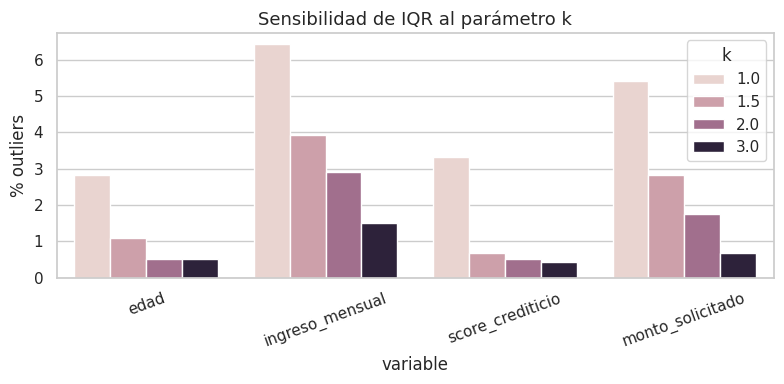

In [36]:
sens = []
for col in ["edad", "ingreso_mensual", "score_crediticio", "monto_solicitado"]:
    for k in [1.0, 1.5, 2.0, 3.0]:
        sens.append({
            "variable": col,
            "k": k,
            "n_outliers": int(flag_iqr(df[col], k=k).sum()),
            "pct": round(flag_iqr(df[col], k=k).mean() * 100, 2),
        })
sens_df = pd.DataFrame(sens)
display(sens_df.pivot(index="variable", columns="k", values="n_outliers"))

plt.figure(figsize=(8, 4))
sns.barplot(data=sens_df, x="variable", y="pct", hue="k")
plt.ylabel("% outliers")
plt.title("Sensibilidad de IQR al parámetro k")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 3.5 Método de percentiles (P1 / P99)

Muy usado en pipelines de producción: simple, interpretable y fácil de documentar.


In [37]:
def flag_percentile(series: pd.Series, low_q: float = 0.01, high_q: float = 0.99) -> pd.Series:
    lo = series.quantile(low_q)
    hi = series.quantile(high_q)
    return (series < lo) | (series > hi)


for col in ["edad", "ingreso_mensual", "score_crediticio", "monto_solicitado"]:
    n_out = flag_percentile(df[col]).sum()
    lo, hi = df[col].quantile(0.01), df[col].quantile(0.99)
    print(f"{col:20s} fuera de [P1={lo:,.1f}, P99={hi:,.1f}] → {n_out}")

edad                 fuera de [P1=18.0, P99=63.0] → 13
ingreso_mensual      fuera de [P1=16,438.0, P99=176,034.8] → 24
score_crediticio     fuera de [P1=469.5, P99=845.4] → 24
monto_solicitado     fuera de [P1=51,039.5, P99=795,198.4] → 24


### 3.7 Qué hacer con los outliers

| Acción | Cuándo |
|--------|--------|
| **Eliminar** | Error claro / fuera de reglas de negocio |
| **Winsorizar** | Mantener la fila pero capear extremos |
| **Transformar** | Sesgo fuerte (ej. `log1p` en ingresos) |
| **Dejar** | El extremo es real y el modelo lo tolera |

Vamos a: (1) eliminar outliers de negocio, (2) winsorizar ingresos por IQR, (3) comparar con transformación log.


In [38]:
# 2) Winsorización de ingreso (cap a límites IQR)
low_i, high_i, *_ = iqr_bounds(df["ingreso_mensual"])
df["ingreso_mensual_winsor"] = df["ingreso_mensual"].clip(lower=low_i, upper=high_i)
# 3) Versión log (no elimina outliers, comprime la escala)  (revisar el caso de uso)
df["ingreso_mensual_log"] = np.log1p(df["ingreso_mensual"])
print(
    f"Ingreso original  min/max: "
    f"{df['ingreso_mensual'].min():,.0f} / {df['ingreso_mensual'].max():,.0f}"
)
print(
    f"Ingreso winsor    min/max: "
    f"{df['ingreso_mensual_winsor'].min():,.0f} / {df['ingreso_mensual_winsor'].max():,.0f}"
)
print(f"Ingreso log       min/max: {df['ingreso_mensual_log'].min():.3f} / {df['ingreso_mensual_log'].max():.3f}")

Ingreso original  min/max: 12,349 / 7,862,320
Ingreso winsor    min/max: 12,349 / 110,304
Ingreso log       min/max: 9.421 / 15.878


### Ejemplo — Antes / después en números

Documentar el impacto de la limpieza es tan importante como limpiar.


### Checklist de cierre

- [ ] Sé explicar MCAR / MAR / MNAR con un ejemplo
- [ ] Sé armar un reporte de missings (`isna`, %)
- [ ] Sé comparar el costo de `dropna` vs imputar
- [ ] Sé imputar numéricas y categóricas con criterio
- [ ] Sé detectar outliers con IQR, Z-score, percentiles y MAD
- [ ] Sé elegir entre eliminar, winsorizar o transformar
- [ ] Tengo un pipeline reproducible de limpieza
- [ ] Sé validar el resultado con checks post-limpieza

### Para llevar a casa

1. Reemplazá el dataset sintético por un CSV propio (`pd.read_csv`).
2. Probá `SimpleImputer` / `KNNImputer` de scikit-learn.
3. Investigá Isolation Forest como detector multivariado de outliers.
4. Armá un informe de 1 página: % missings, método elegido, outliers removidos, impacto en media/mediana.
5. Rehacé el EDA de `ingreso_mensual` **solo en escala log** y compará conclusiones.


---
## Referencia rápida de código

```python
df.info()
df.describe()
df.isna().mean()
df.fillna(df.median(numeric_only=True))
df.groupby("segmento")["ingreso"].transform(lambda s: s.fillna(s.median()))

q1, q3 = s.quantile(0.25), s.quantile(0.75)
low, high = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
s.clip(low, high)            # winsorizar
s[(s >= low) & (s <= high)]  # filtrar

# Percentiles / MAD
lo, hi = s.quantile(0.01), s.quantile(0.99)
mad = (s - s.median()).abs().median()
mz = 0.6745 * (s - s.median()) / mad
```

**JUMP Educación** — Exploración · Missings · Outliers · Python · Versión extendida
